# Intelligent Market Regime and Risk Analyzer
## Stock Price Data Preprocessing and Feature Engineering

**Course:** Data Science Tools and Techniques (DSTT)

**Project:** Intelligent Market Regime and Risk Analyzer

**Team Members:** Hamza Ahmed, Sikandar Mukhtar, Tayyab Akhtar

**Prepared By:** Hamza Ahmed

**Dataset:** Historical Stock Prices (2015–2023)

---

### Project Overview

This project focuses on analyzing historical stock market data to understand stock performance and market risk. The stock price dataset contains daily trading information for six different stocks from 2015 to 2023.

This notebook covers the preprocessing, data cleaning, validation, and feature engineering of the stock price dataset. Different financial features will be calculated to help understand stock returns, price movements, volatility, and market risk.

## Objectives

The main objectives of this notebook are:

1. Understand the structure and characteristics of the stock price dataset.
2. Identify and handle data quality issues.
3. Clean and validate stock price records.
4. Perform statistical analysis before and after feature engineering.
5. Calculate important financial features such as returns, moving averages, volatility, and drawdown.
6. Prepare a clean dataset for future market risk analysis and machine learning tasks.

###Importing The Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)

sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving filtered_stock_prices.csv to filtered_stock_prices.csv


In [3]:
# Load stock price dataset
df = pd.read_csv('filtered_stock_prices.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 1. Understanding the Stock Price Dataset

Before performing preprocessing, it is important to understand the structure of our dataset. This section examines the dataset dimensions, column names, data types, stock symbols, and sample records.

This initial inspection helps us understand what information is available and identify areas that may require further checking.

In [5]:
# Display first five records
print("First five rows:")
display(df.head())

# Display last five records
print("Last five rows:")
display(df.tail())

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Unique stock tickers
print("\nStock tickers:")
print(df['ticker'].unique())

# Number of records for each stock
print("\nRecords per stock:")
display(df['ticker'].value_counts())

First five rows:


,date,ticker,open,high,low,close,adj_close,volume
0,2015-01-02 00:00:00+00:00,COST,141.869995,143.149994,140.809998,141.610001,124.577209,1471000
1,2015-01-05 00:00:00+00:00,COST,141.690002,142.160004,139.800003,140.000000,123.160820,1748500
2,2015-01-06 00:00:00+00:00,COST,140.610001,142.940002,139.850006,141.850006,124.788300,3185200
3,2015-01-07 00:00:00+00:00,COST,142.600006,144.429993,142.360001,144.320007,126.961243,2171600
4,2015-01-08 00:00:00+00:00,COST,145.559998,146.100006,144.940002,145.559998,128.052032,2937700


Last five rows:


,date,ticker,open,high,low,close,adj_close,volume
13573,2023-12-21 00:00:00+00:00,WFC,49.619999,49.830002,49.130001,49.450001,49.450001,11127700
13574,2023-12-22 00:00:00+00:00,WFC,49.660000,49.860001,49.090000,49.180000,49.180000,10448000
13575,2023-12-26 00:00:00+00:00,WFC,49.160000,49.669998,49.029999,49.639999,49.639999,8856600
13576,2023-12-27 00:00:00+00:00,WFC,49.410000,49.570000,49.150002,49.330002,49.330002,12536700
13577,2023-12-28 00:00:00+00:00,WFC,49.139999,49.650002,49.090000,49.480000,49.480000,9872600


Dataset shape: (13578, 8)

Column names:
['date', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume']

Data types:
date          object
ticker        object
open         float64
high         float64
low          float64
close        float64
adj_close    float64
volume         int64
dtype: object

Stock tickers:
['COST' 'MRK' 'NVDA' 'OXY' 'SPY' 'WFC']

Records per stock:


,count
ticker,
COST,2263
MRK,2263
NVDA,2263
OXY,2263
SPY,2263
WFC,2263


One thing to notice: the date column is currently stored as an object. We will convert it into a proper datetime format during preprocessing.

## 2. Initial Statistical Analysis

Descriptive statistics are used to understand the numerical characteristics of the dataset. We calculate the mean, standard deviation, minimum, maximum, and quartile values of the stock prices and trading volume.

This analysis provides an initial understanding of price ranges, trading activity, and differences between stocks before applying any cleaning or feature engineering techniques.

In [6]:
# Generate descriptive statistics
statistics_before = df.describe()

# Display statistics table
display(statistics_before.round(2))

,open,high,low,close,adj_close,volume
count,13578.00,13578.00,13578.00,13578.00,13578.00,1.357800e+04
mean,150.85,152.23,149.43,150.89,145.22,3.122136e+07
std,141.78,142.92,140.61,141.85,138.63,3.788031e+07
min,4.81,4.88,4.74,4.78,4.60,4.910000e+05
25%,52.93,53.44,52.37,52.90,50.28,6.175450e+06
50%,75.93,76.61,75.27,75.99,68.57,1.641410e+07
75%,223.87,226.07,220.98,223.83,217.46,4.492605e+07
max,675.00,681.91,670.78,681.24,666.80,5.072443e+08


Now let's generate statistics separately for each stock.

In [7]:
# Calculate statistics for each stock
stock_statistics_before = df.groupby('ticker')[
    ['open', 'high', 'low', 'close', 'adj_close', 'volume']
].agg(['mean', 'std', 'min', 'max'])

# Display the table
display(stock_statistics_before.round(2))

open                            high                          \
          mean     std     min     max    mean     std     min     max   
ticker                                                                   
COST    303.54  147.58  131.97  675.00  306.22  149.15  136.57  681.91   
MRK      75.05   16.86   48.58  118.35   75.70   17.03   49.11  119.65   
NVDA    111.13  119.39    4.81  502.16  113.14  121.44    4.88  505.48   
OXY      56.14   20.39    8.70   87.00   56.86   20.45    9.16   87.67   
SPY     311.94   86.67  182.34  479.22  313.70   87.25  184.10  479.98   
WFC      47.27    8.84   21.05   65.89   47.76    8.81   21.38   66.31   

           low                           close                          \
          mean     std     min     max    mean     std     min     max   
ticker                                                                   
COST    300.92  146.09  117.03  670.78  303.72  147.73  132.71  681.24   
MRK      74.38   16.70   45.69  117.93   75.05   16.88   48.42  118.38   
NVDA    109.05  117.19    4.74  494.12  111.19  119.39    4.78  504.09   
OXY      55.38   20.30    8.52   86.17   56.12   20.39    8.88   86.48   
SPY     310.05   86.07  181.02  476.26  312.00   86.69  182.86  477.71   
WFC      46.79    8.87   20.76   65.66   47.27    8.84   21.14   65.93   

       adj_close                               volume                         \
            mean     std     min     max         mean          std       min   
ticker                                                                         
COST      293.18  144.78  121.57  666.80   2367058.37   1329219.52    491000   
MRK        70.39   18.42   41.93  115.96  10429400.84   5266682.09   2235900   
NVDA      110.91  119.44    4.60  504.05  47772939.15  25998744.72   5244800   
OXY        50.07   16.82    8.69   76.55  12491155.99  12888487.65   1319200   
SPY       300.17   89.02  167.40  476.69  90761635.26  45623994.08  20270000   
WFC        46.60    9.26   19.67   65.93  23505957.18  12764171.61   4635500   

                   
              max  
ticker             
COST     24233000  
MRK     102497300  
NVDA    369292800  
OXY     134669000  
SPY     507244300  
WFC     118952600

### Observations from Stock-wise Descriptive Statistics

The statistical analysis shows differences in price levels and trading activity among the six stocks. NVDA has the highest standard deviation in adjusted closing prices, while SPY has the highest average trading volume. COST also shows a wide range of adjusted closing prices during the selected period.

OXY shows considerable variation in its trading volume, while WFC and MRK have relatively lower average price levels. These differences highlight the importance of analyzing each stock separately when studying market performance and risk.

These results provide an initial understanding of the dataset before cleaning and feature engineering.

## 3. Data Quality Inspection

In this section, we will examine the dataset for missing values, duplicate records, and incorrect data types. These checks are important because data quality problems can affect statistical analysis and future calculations.

We will first inspect the original dataset to understand its condition before applying any cleaning operations.

In [8]:
# Check missing values
print("Missing Values:")
display(df.isnull().sum())

# Check total missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Check exact duplicate rows
print("\nExact Duplicate Rows:", df.duplicated().sum())

# Check duplicate ticker-date records
print("Duplicate Ticker-Date Records:",
      df.duplicated(subset=['ticker', 'date']).sum())

# Check dataset information
print("\nDataset Information:")
df.info()

Missing Values:


,0
date,0
ticker,0
open,0
high,0
low,0
close,0
adj_close,0
volume,0


Total Missing Values: 0

Exact Duplicate Rows: 0
Duplicate Ticker-Date Records: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13578 entries, 0 to 13577
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       13578 non-null  object 
 1   ticker     13578 non-null  object 
 2   open       13578 non-null  float64
 3   high       13578 non-null  float64
 4   low        13578 non-null  float64
 5   close      13578 non-null  float64
 6   adj_close  13578 non-null  float64
 7   volume     13578 non-null  int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 848.8+ KB


### Data Quality Inspection Findings

The dataset contains 13,578 records with no missing values, exact duplicate rows, or duplicate ticker-date combinations. All numerical columns are already stored in appropriate numeric formats.

However, the date column is stored as an object data type and needs conversion into datetime format. Overall, the initial inspection indicates that the dataset has good data quality and requires only basic preprocessing and validation.

## 4. Data Cleaning and Preprocessing

In this section, we will prepare the stock price dataset for further analysis. We will standardize column names, convert the date column into datetime format, check numerical data types, remove exact duplicate records if present, and arrange the records by stock ticker and date.

The original dataset will remain unchanged, and all preprocessing operations will be performed on a separate copy.

In [10]:
# Keep a copy of the original dataset
raw_df = df.copy()

# Create a separate dataset for cleaning
clean_df = df.copy()

# Standardize column names
clean_df.columns = clean_df.columns.str.strip().str.lower()

# Convert date column into datetime format
clean_df['date'] = pd.to_datetime(
    clean_df['date'],
    errors='coerce',
    utc=True
).dt.normalize()

# Convert numerical columns into numeric format
numeric_columns = [
    'open', 'high', 'low', 'close', 'adj_close', 'volume'
]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(
        clean_df[col],
        errors='coerce'
    )

# Count exact duplicates before removal
duplicates_before = clean_df.duplicated().sum()

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Sort records by ticker and date
clean_df = clean_df.sort_values(
    by=['ticker', 'date']
).reset_index(drop=True)

# Display results
print("Cleaning completed successfully!")

print("Original rows:", len(raw_df))
print("Rows after cleaning:", len(clean_df))
print("Duplicates removed:", duplicates_before)

print("\nUpdated data types:")
print(clean_df.dtypes)

display(clean_df.head())

Cleaning completed successfully!
Original rows: 13578
Rows after cleaning: 13578
Duplicates removed: 0

Updated data types:
date         datetime64[ns, UTC]
ticker                    object
open                     float64
high                     float64
low                      float64
close                    float64
adj_close                float64
volume                     int64
dtype: object


,date,ticker,open,high,low,close,adj_close,volume
0,2015-01-02 00:00:00+00:00,COST,141.869995,143.149994,140.809998,141.610001,124.577209,1471000
1,2015-01-05 00:00:00+00:00,COST,141.690002,142.160004,139.800003,140.000000,123.160820,1748500
2,2015-01-06 00:00:00+00:00,COST,140.610001,142.940002,139.850006,141.850006,124.788300,3185200
3,2015-01-07 00:00:00+00:00,COST,142.600006,144.429993,142.360001,144.320007,126.961243,2171600
4,2015-01-08 00:00:00+00:00,COST,145.559998,146.100006,144.940002,145.559998,128.052032,2937700


### Post-Cleaning Data Quality Check

After cleaning and converting the columns to their appropriate data types, we check the dataset again for missing values and duplicate ticker-date records. This helps confirm that the cleaning process has not introduced any data quality issues.

In [11]:
print("Missing Values After Cleaning:")
display(clean_df.isnull().sum())

print("Total Missing Values:", clean_df.isnull().sum().sum())

print("\nDuplicate Ticker-Date Records:")
print(clean_df.duplicated(subset=['ticker', 'date']).sum())

Missing Values After Cleaning:


,0
date,0
ticker,0
open,0
high,0
low,0
close,0
adj_close,0
volume,0


Total Missing Values: 0

Duplicate Ticker-Date Records:
0


The post-cleaning validation confirms that the dataset contains no missing values and no duplicate ticker-date records. All 13,578 observations have been preserved, indicating that the cleaning process maintained the completeness and structure of the original stock price data.

### Logical Validation of Stock Data

In this step, we check the dataset for logically incorrect values. We verify that prices are positive, trading volume is non-negative, the highest price is not below the lowest price, and opening and closing prices fall within the daily high-low range. These checks help identify inconsistencies that may affect further analysis.

In [12]:
# Check for non-positive prices
price_columns = ['open', 'high', 'low', 'close', 'adj_close']

non_positive_prices = (clean_df[price_columns] <= 0).sum()

# Check for negative trading volume
negative_volume = (clean_df['volume'] < 0).sum()

# Check if high price is lower than low price
invalid_high_low = (clean_df['high'] < clean_df['low']).sum()

# Check if open and close prices are outside the high-low range
invalid_open = (
    (clean_df['open'] < clean_df['low']) |
    (clean_df['open'] > clean_df['high'])
).sum()

invalid_close = (
    (clean_df['close'] < clean_df['low']) |
    (clean_df['close'] > clean_df['high'])
).sum()

print("Non-Positive Prices:")
display(non_positive_prices)

print("Negative Volume:", negative_volume)
print("High Below Low:", invalid_high_low)
print("Open Outside High-Low Range:", invalid_open)
print("Close Outside High-Low Range:", invalid_close)

Non-Positive Prices:


,0
open,0
high,0
low,0
close,0
adj_close,0


Negative Volume: 0
High Below Low: 0
Open Outside High-Low Range: 0
Close Outside High-Low Range: 0


**Interpretation:**

The dataset passed all logical validation checks. All stock prices are positive, trading volumes are non-negative, and OHLC values follow the expected price relationships. No invalid records were found, so no rows needed to be removed during logical validation.

### Trading Date Consistency Check

Different stocks should generally have observations for the same trading dates. We use SPY as the reference trading calendar and compare the dates of each stock against it. This helps identify missing trading-day records without treating weekends and market holidays as missing data.

In [13]:
spy_dates = set(clean_df.loc[clean_df['ticker'] == 'SPY', 'date'])

missing_dates = []

for ticker in clean_df['ticker'].unique():
    stock_dates = set(clean_df.loc[clean_df['ticker'] == ticker, 'date'])

    missing = spy_dates - stock_dates

    missing_dates.append({
        'ticker': ticker,
        'missing_trading_dates': len(missing)
    })

missing_dates_df = pd.DataFrame(missing_dates)

display(missing_dates_df)

,ticker,missing_trading_dates
0,COST,0
1,MRK,0
2,NVDA,0
3,OXY,0
4,SPY,0
5,WFC,0


**Interpretation:**

All six stocks have zero missing trading dates when compared with SPY's trading calendar. This confirms that the dataset has consistent trading-date coverage across all selected stocks, and no additional date-related cleaning is required.

##5. Outlier Detection

In this step, we identify unusually large daily price movements and trading-volume spikes. These observations are flagged for inspection rather than automatically removed, as they may represent genuine market events.

In [14]:
clean_df['daily_return'] = (
    clean_df.groupby('ticker')['adj_close'].pct_change()
)

clean_df['volume_change'] = (
    clean_df.groupby('ticker')['volume'].pct_change()
)

# Identify extreme daily returns
extreme_returns = clean_df[
    clean_df['daily_return'].abs() > 0.10
]

# Identify unusually high trading volumes
volume_threshold = clean_df.groupby('ticker')['volume'].transform(
    lambda x: x.quantile(0.99)
)

volume_spikes = clean_df[clean_df['volume'] > volume_threshold]

print("Extreme Daily Returns (> 10%):", len(extreme_returns))
print("Unusual Volume Spikes (Top 1%):", len(volume_spikes))

print("\nExtreme Return Examples:")
display(extreme_returns[['date', 'ticker', 'daily_return']].head())

print("\nVolume Spike Examples:")
display(volume_spikes[['date', 'ticker', 'volume']].head())

Extreme Daily Returns (> 10%): 57
Unusual Volume Spikes (Top 1%): 138

Extreme Return Examples:


,date,ticker,daily_return
1857,2022-05-18 00:00:00+00:00,COST,-0.124513
2664,2016-08-05 00:00:00+00:00,MRK,0.104080
3648,2020-07-06 00:00:00+00:00,MRK,-0.136533
4676,2015-08-07 00:00:00+00:00,NVDA,0.123717
4740,2015-11-06 00:00:00+00:00,NVDA,0.138578



Volume Spike Examples:


,date,ticker,volume
21,2015-02-03 00:00:00+00:00,COST,10302900
22,2015-02-04 00:00:00+00:00,COST,11006300
236,2015-12-09 00:00:00+00:00,COST,9527000
352,2016-05-26 00:00:00+00:00,COST,7679400
545,2017-03-03 00:00:00+00:00,COST,10396500


**Interpretation:**

The outlier analysis identified 57 extreme daily returns and 138 unusual trading-volume observations. These values may reflect genuine market events, earnings announcements, or unusual trading activity. Therefore, they are retained in the dataset rather than automatically removed.

### Outlier Quantile Analysis
This section examines the distribution of daily returns and trading volumes to understand unusually large movements. Quantiles help identify extreme values that may require further investigation.

In [27]:
# Calculate daily return quantiles for each stock
return_quantiles = clean_df.groupby('ticker')['daily_return'].quantile(
    [0.01, 0.50, 0.99]
).unstack()

return_quantiles.columns = ['1% Quantile', 'Median', '99% Quantile']

print("Daily Return Quantiles:")
display(return_quantiles)

# Calculate trading volume quantiles for each stock
volume_quantiles = clean_df.groupby('ticker')['volume'].quantile(
    [0.50, 0.99]
).unstack()

volume_quantiles.columns = ['Median Volume', '99% Quantile']

print("Trading Volume Quantiles:")
display(volume_quantiles)

Daily Return Quantiles:


,1% Quantile,Median,99% Quantile
ticker,,,
COST,-0.040692,0.001208,0.039034
MRK,-0.037989,0.000365,0.039333
NVDA,-0.074178,0.002537,0.079645
OXY,-0.076309,0.000000,0.092120
SPY,-0.033195,0.000552,0.026891
WFC,-0.056647,0.000000,0.056154


Trading Volume Quantiles:


,Median Volume,99% Quantile
ticker,,
COST,2034700.0,7325510.0
MRK,9368400.0,29362856.0
NVDA,42416000.0,141536272.0
OXY,7554000.0,61306828.0
SPY,78882900.0,276197650.0
WFC,19490100.0,72512710.0


###Plot 1: Daily return outliers

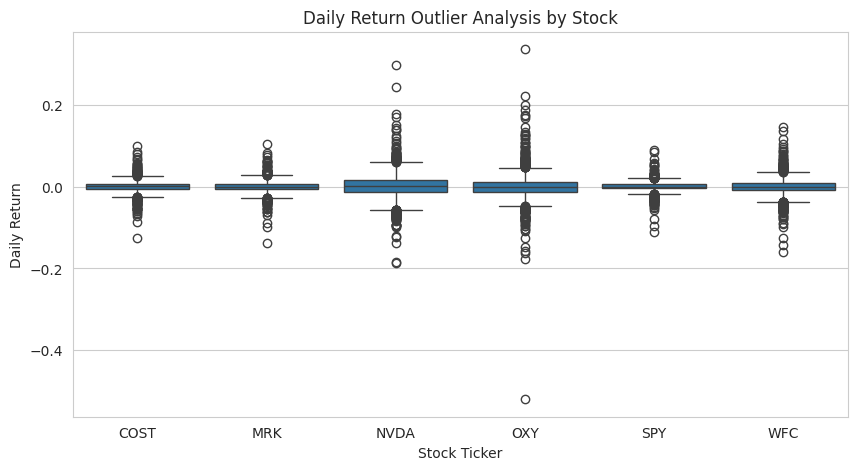

In [29]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=clean_df, x='ticker', y='daily_return')

plt.title('Daily Return Outlier Analysis by Stock')
plt.xlabel('Stock Ticker')
plt.ylabel('Daily Return')
plt.show()

###Plot 2: Trading volume outliers

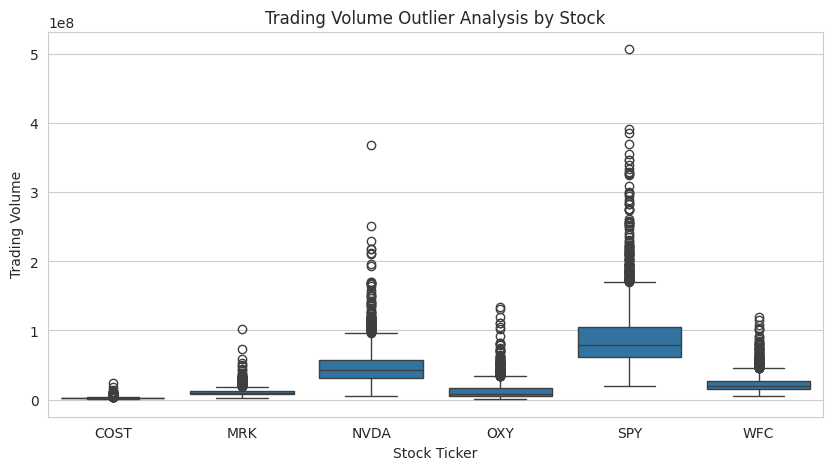

In [30]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=clean_df, x='ticker', y='volume')

plt.title('Trading Volume Outlier Analysis by Stock')
plt.xlabel('Stock Ticker')
plt.ylabel('Trading Volume')
plt.show()

The boxplots show the distribution of daily returns and trading volumes across the six stocks. Some observations extend beyond the typical ranges, indicating potential outliers. These observations are retained because they may represent genuine market events or unusual trading activity rather than data errors.

##6. Feature Engineering

Feature engineering creates additional variables from historical stock prices. These features help describe stock performance, price movements, and market risk.

**Features Created**

We created 12 new features to describe stock price movements, performance, trading activity, and market risk:

- **Daily Return:** Measures the percentage change in adjusted closing price from the previous trading day.
- **Log Return:** Calculates the logarithmic return between consecutive trading days.
- **5-Day Return:** Measures stock performance over the previous 5 trading sessions.
- **20-Day Return:** Measures stock performance over the previous 20 trading sessions.
- **SMA 20:** Calculates the average adjusted closing price over 20 trading sessions.
- **SMA 50:** Calculates the average adjusted closing price over 50 trading sessions.
- **20-Day Volatility:** Measures fluctuations in daily returns over 20 sessions, annualized.
- **Volume Change:** Measures the percentage change in trading volume.
- **Drawdown:** Measures the decline in price from its previous highest level.
- **SPY Return:** Represents the daily return of the SPY market benchmark.
- **Excess Return:** Measures stock return relative to the SPY benchmark.
- **60-Day Beta:** Measures how sensitive a stock's returns are to market movements over 60 sessions.

These features provide useful information for understanding stock performance and analyzing market risk.

In [15]:
# Daily percentage return
clean_df['daily_return'] = (
    clean_df.groupby('ticker')['adj_close'].pct_change()
)

# Logarithmic daily return
clean_df['log_return'] = np.log(
    clean_df['adj_close'] /
    clean_df.groupby('ticker')['adj_close'].shift(1)
)

display(clean_df[['date', 'ticker', 'adj_close',
                  'daily_return', 'log_return']].head(10))

,date,ticker,adj_close,daily_return,log_return
0,2015-01-02 00:00:00+00:00,COST,124.577209,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,123.160820,-0.011370,-0.011435
2,2015-01-06 00:00:00+00:00,COST,124.788300,0.013214,0.013128
3,2015-01-07 00:00:00+00:00,COST,126.961243,0.017413,0.017263
4,2015-01-08 00:00:00+00:00,COST,128.052032,0.008592,0.008555
5,2015-01-09 00:00:00+00:00,COST,126.081551,-0.015388,-0.015508
6,2015-01-12 00:00:00+00:00,COST,125.377754,-0.005582,-0.005598
7,2015-01-13 00:00:00+00:00,COST,124.119743,-0.010034,-0.010084
8,2015-01-14 00:00:00+00:00,COST,122.553848,-0.012616,-0.012696
9,2015-01-15 00:00:00+00:00,COST,122.553848,0.000000,0.000000


**Interpretation:**

Daily returns and logarithmic returns were successfully calculated using adjusted closing prices. The first observation for each stock contains a missing value because no previous trading-day price is available. Positive and negative values represent price increases and decreases, respectively.

In [16]:
clean_df['return_5d'] = (
    clean_df.groupby('ticker')['adj_close'].pct_change(periods=5)
)

clean_df['return_20d'] = (
    clean_df.groupby('ticker')['adj_close'].pct_change(periods=20)
)

display(clean_df[['date', 'ticker', 'adj_close',
                  'return_5d', 'return_20d']].head(25))

,date,ticker,adj_close,return_5d,return_20d
0,2015-01-02 00:00:00+00:00,COST,124.577209,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,123.160820,NaN,NaN
2,2015-01-06 00:00:00+00:00,COST,124.788300,NaN,NaN
3,2015-01-07 00:00:00+00:00,COST,126.961243,NaN,NaN
4,2015-01-08 00:00:00+00:00,COST,128.052032,NaN,NaN
5,2015-01-09 00:00:00+00:00,COST,126.081551,0.012076,NaN
6,2015-01-12 00:00:00+00:00,COST,125.377754,0.018000,NaN
7,2015-01-13 00:00:00+00:00,COST,124.119743,-0.005358,NaN
8,2015-01-14 00:00:00+00:00,COST,122.553848,-0.034714,NaN
9,2015-01-15 00:00:00+00:00,COST,122.553848,-0.042937,NaN


**Interpretation:**

The 5-day and 20-day returns were successfully calculated to measure short-term and medium-term stock performance. Initial observations contain missing values because sufficient historical trading data is required for these calculations.

In [17]:
clean_df['sma_20'] = (
    clean_df.groupby('ticker')['adj_close']
    .transform(lambda x: x.rolling(window=20).mean())
)

clean_df['sma_50'] = (
    clean_df.groupby('ticker')['adj_close']
    .transform(lambda x: x.rolling(window=50).mean())
)

display(clean_df[['date', 'ticker', 'adj_close',
                  'sma_20', 'sma_50']].head(55))

,date,ticker,adj_close,sma_20,sma_50
0,2015-01-02 00:00:00+00:00,COST,124.577209,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,123.160820,NaN,NaN
2,2015-01-06 00:00:00+00:00,COST,124.788300,NaN,NaN
3,2015-01-07 00:00:00+00:00,COST,126.961243,NaN,NaN
4,2015-01-08 00:00:00+00:00,COST,128.052032,NaN,NaN
5,2015-01-09 00:00:00+00:00,COST,126.081551,NaN,NaN
6,2015-01-12 00:00:00+00:00,COST,125.377754,NaN,NaN
7,2015-01-13 00:00:00+00:00,COST,124.119743,NaN,NaN
8,2015-01-14 00:00:00+00:00,COST,122.553848,NaN,NaN
9,2015-01-15 00:00:00+00:00,COST,122.553848,NaN,NaN


**Interpretation:**

The 20-day and 50-day Simple Moving Averages were successfully calculated using adjusted closing prices. These indicators help identify short-term and longer-term price trends. Initial observations contain missing values until the required number of trading sessions is available.

In [18]:
clean_df['volatility_20'] = (
    clean_df.groupby('ticker')['daily_return']
    .transform(lambda x: x.rolling(window=20).std() * np.sqrt(252))
)

display(clean_df[['date', 'ticker', 'daily_return',
                  'volatility_20']].head(25))

,date,ticker,daily_return,volatility_20
0,2015-01-02 00:00:00+00:00,COST,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,-0.011370,NaN
2,2015-01-06 00:00:00+00:00,COST,0.013214,NaN
3,2015-01-07 00:00:00+00:00,COST,0.017413,NaN
4,2015-01-08 00:00:00+00:00,COST,0.008592,NaN
5,2015-01-09 00:00:00+00:00,COST,-0.015388,NaN
6,2015-01-12 00:00:00+00:00,COST,-0.005582,NaN
7,2015-01-13 00:00:00+00:00,COST,-0.010034,NaN
8,2015-01-14 00:00:00+00:00,COST,-0.012616,NaN
9,2015-01-15 00:00:00+00:00,COST,0.000000,NaN


**Interpretation:**

The 20-day rolling volatility was successfully calculated and annualized using 252 trading days. It measures the fluctuations in stock returns over time. Higher values indicate greater price variability and potentially higher investment risk.

In [19]:
# Percentage change in trading volume
clean_df['volume_change'] = (
    clean_df.groupby('ticker')['volume'].pct_change()
)

# Historical maximum adjusted closing price
running_max = clean_df.groupby('ticker')['adj_close'].cummax()

# Drawdown from historical maximum
clean_df['drawdown'] = (
    clean_df['adj_close'] / running_max
) - 1

display(clean_df[['date', 'ticker', 'volume',
                  'volume_change', 'adj_close',
                  'drawdown']].head(15))

,date,ticker,volume,volume_change,adj_close,drawdown
0,2015-01-02 00:00:00+00:00,COST,1471000,NaN,124.577209,0.000000
1,2015-01-05 00:00:00+00:00,COST,1748500,0.188647,123.160820,-0.011370
2,2015-01-06 00:00:00+00:00,COST,3185200,0.821676,124.788300,0.000000
3,2015-01-07 00:00:00+00:00,COST,2171600,-0.318222,126.961243,0.000000
4,2015-01-08 00:00:00+00:00,COST,2937700,0.352781,128.052032,0.000000
5,2015-01-09 00:00:00+00:00,COST,1727000,-0.412125,126.081551,-0.015388
6,2015-01-12 00:00:00+00:00,COST,1344800,-0.221309,125.377754,-0.020884
7,2015-01-13 00:00:00+00:00,COST,2198500,0.634816,124.119743,-0.030709
8,2015-01-14 00:00:00+00:00,COST,2207900,0.004276,122.553848,-0.042937
9,2015-01-15 00:00:00+00:00,COST,1819600,-0.175868,122.553848,-0.042937


**Interpretation:**

Volume change and drawdown were successfully calculated. Volume change shows increases or decreases in trading activity compared with the previous session. Drawdown measures the decline from the stock's highest historical adjusted closing price. Negative drawdown values indicate that the stock is trading below its previous peak.

Now we'll compare each stock's daily performance with the S&P 500 benchmark (SPY).

In [20]:
# Extract SPY daily returns
spy_returns = clean_df.loc[
    clean_df['ticker'] == 'SPY',
    ['date', 'daily_return']
].rename(columns={'daily_return': 'spy_return'})

# Merge SPY returns with all stocks using trading date
clean_df = clean_df.merge(
    spy_returns,
    on='date',
    how='left'
)

# Calculate excess return
clean_df['excess_return'] = (
    clean_df['daily_return'] - clean_df['spy_return']
)

display(clean_df[['date', 'ticker', 'daily_return',
                  'spy_return', 'excess_return']].head(15))

,date,ticker,daily_return,spy_return,excess_return
0,2015-01-02 00:00:00+00:00,COST,NaN,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,-0.011370,-0.018060,0.006690
2,2015-01-06 00:00:00+00:00,COST,0.013214,-0.009419,0.022633
3,2015-01-07 00:00:00+00:00,COST,0.017413,0.012461,0.004952
4,2015-01-08 00:00:00+00:00,COST,0.008592,0.017745,-0.009153
5,2015-01-09 00:00:00+00:00,COST,-0.015388,-0.008014,-0.007375
6,2015-01-12 00:00:00+00:00,COST,-0.005582,-0.007834,0.002252
7,2015-01-13 00:00:00+00:00,COST,-0.010034,-0.002813,-0.007221
8,2015-01-14 00:00:00+00:00,COST,-0.012616,-0.006037,-0.006579
9,2015-01-15 00:00:00+00:00,COST,0.000000,-0.009161,0.009161


**Interpretation:**

SPY daily returns were successfully added as a market benchmark, and excess returns were calculated for each stock. Positive excess returns indicate outperformance compared with SPY, while negative values indicate underperformance. These features help evaluate individual stock performance relative to the overall market.

In [21]:
# Calculate rolling covariance between each stock and SPY
rolling_cov = clean_df.groupby('ticker').apply(
    lambda group: group['daily_return'].rolling(60).cov(
        group['spy_return']
    ),
    include_groups=False
).reset_index(level=0, drop=True)

# Calculate rolling SPY variance
spy_variance = clean_df.groupby('ticker')['spy_return'].transform(
    lambda x: x.rolling(60).var()
)

# Calculate rolling beta
clean_df['beta_60'] = rolling_cov / spy_variance

display(clean_df[['date', 'ticker', 'daily_return',
                  'spy_return', 'beta_60']].head(70))

,date,ticker,daily_return,spy_return,beta_60
0,2015-01-02 00:00:00+00:00,COST,NaN,NaN,NaN
1,2015-01-05 00:00:00+00:00,COST,-0.011370,-0.018060,NaN
2,2015-01-06 00:00:00+00:00,COST,0.013214,-0.009419,NaN
3,2015-01-07 00:00:00+00:00,COST,0.017413,0.012461,NaN
4,2015-01-08 00:00:00+00:00,COST,0.008592,0.017745,NaN
...,...,...,...,...,...
65,2015-04-08 00:00:00+00:00,COST,0.001450,0.003377,0.783664
66,2015-04-09 00:00:00+00:00,COST,-0.020987,0.004423,0.755584
67,2015-04-10 00:00:00+00:00,COST,0.005578,0.005457,0.747865
68,2015-04-13 00:00:00+00:00,COST,-0.004143,-0.004523,0.733656


**Interpretation:**

The 60-day rolling beta was successfully calculated using the covariance between individual stock returns and SPY returns. It measures each stock's sensitivity to market movements. Initial observations contain missing values until sufficient historical data is available.

### Feature Validation and Statistics

Now we need to check whether all engineered features were created successfully and identify their missing values.

In [22]:
feature_columns = [
    'daily_return',
    'log_return',
    'return_5d',
    'return_20d',
    'sma_20',
    'sma_50',
    'volatility_20',
    'volume_change',
    'drawdown',
    'spy_return',
    'excess_return',
    'beta_60'
]

print("Feature Dataset Shape:", clean_df.shape)

print("\nMissing Values in Engineered Features:")
display(clean_df[feature_columns].isnull().sum())

print("\nFeature Statistics:")
display(clean_df[feature_columns].describe())

Feature Dataset Shape: (13578, 20)

Missing Values in Engineered Features:


,0
daily_return,6
log_return,6
return_5d,30
return_20d,120
sma_20,114
sma_50,294
volatility_20,120
volume_change,6
drawdown,0
spy_return,6



Feature Statistics:


,daily_return,log_return,return_5d,return_20d,sma_20,sma_50,volatility_20,volume_change,drawdown,spy_return,excess_return,beta_60
count,13572.000000,13572.000000,13548.000000,13458.000000,13464.000000,13284.000000,13458.000000,13572.000000,13578.000000,13572.000000,13572.000000,13218.000000
mean,0.000824,0.000585,0.004079,0.016352,144.834018,144.314594,0.276784,0.062079,-0.152572,0.000486,0.000338,1.058212
std,0.021703,0.022021,0.047211,0.096041,137.725750,136.579691,0.206791,0.430594,0.177685,0.011422,0.017822,0.557128
min,-0.520138,-0.734257,-0.630805,-0.749763,4.758501,5.009360,0.031906,-0.825074,-0.886536,-0.109424,-0.442044,-0.286725
25%,-0.007540,-0.007569,-0.015509,-0.028485,50.220233,50.194415,0.153290,-0.189069,-0.203155,-0.003820,-0.005833,0.704151
50%,0.000641,0.000641,0.003861,0.014892,68.467871,68.503109,0.218163,-0.014019,-0.089921,0.000552,0.000000,1.000000
75%,0.009069,0.009028,0.022904,0.055599,217.648117,217.666277,0.327009,0.215719,-0.025801,0.005932,0.005801,1.206629
max,0.336978,0.290412,0.766836,0.882883,625.722952,584.693932,2.563497,12.817425,0.000000,0.090603,0.311348,3.304441


**Interpretation:**

The feature engineering process successfully generated 12 new features, increasing the dataset to 20 columns while preserving all 13,578 records. The missing values in return, moving average, volatility, and beta features occur naturally because these calculations require previous trading sessions. The descriptive statistics show variations in stock returns, trading volume, volatility, and market sensitivity. These features will help analyze stock performance and market risk.

Now we will move with the final dataset validation

In [23]:
print("Infinite Values in Numerical Columns:")
display(
    np.isinf(clean_df.select_dtypes(include='number')).sum()
)

print("\nFinal Dataset Shape:", clean_df.shape)

print("Total Duplicate Records:", clean_df.duplicated().sum())

print(
    "Duplicate Ticker-Date Records:",
    clean_df.duplicated(subset=['ticker', 'date']).sum()
)

print("\nNumber of Unique Tickers:", clean_df['ticker'].nunique())

Infinite Values in Numerical Columns:


,0
open,0
high,0
low,0
close,0
adj_close,0
volume,0
daily_return,0
volume_change,0
log_return,0
return_5d,0



Final Dataset Shape: (13578, 20)
Total Duplicate Records: 0
Duplicate Ticker-Date Records: 0

Number of Unique Tickers: 6


**Interpretation:**

The final validation confirms that the feature-engineered dataset contains 13,578 records and 20 columns. No infinite values or duplicate records were found, and all six stock tickers are present. The dataset successfully passed the final integrity checks and is ready for export.

In [24]:
statistics_after = clean_df.describe()

display(statistics_after)

,open,high,low,close,adj_close,volume,daily_return,volume_change,log_return,return_5d,return_20d,sma_20,sma_50,volatility_20,drawdown,spy_return,excess_return,beta_60
count,13578.000000,13578.000000,13578.000000,13578.000000,13578.000000,1.357800e+04,13572.000000,13572.000000,13572.000000,13548.000000,13458.000000,13464.000000,13284.000000,13458.000000,13578.000000,13572.000000,13572.000000,13218.000000
mean,150.846935,152.226681,149.428471,150.890559,145.220008,3.122136e+07,0.000824,0.062079,0.000585,0.004079,0.016352,144.834018,144.314594,0.276784,-0.152572,0.000486,0.000338,1.058212
std,141.775461,142.921607,140.612451,141.845423,138.629054,3.788031e+07,0.021703,0.430594,0.022021,0.047211,0.096041,137.725750,136.579691,0.206791,0.177685,0.011422,0.017822,0.557128
min,4.812500,4.875000,4.735000,4.785000,4.595126,4.910000e+05,-0.520138,-0.825074,-0.734257,-0.630805,-0.749763,4.758501,5.009360,0.031906,-0.886536,-0.109424,-0.442044,-0.286725
25%,52.930000,53.444999,52.372499,52.900002,50.280975,6.175450e+06,-0.007540,-0.189069,-0.007569,-0.015509,-0.028485,50.220233,50.194415,0.153290,-0.203155,-0.003820,-0.005833,0.704151
50%,75.932327,76.614761,75.269997,75.986412,68.572433,1.641410e+07,0.000641,-0.014019,0.000641,0.003861,0.014892,68.467871,68.503109,0.218163,-0.089921,0.000552,0.000000,1.000000
75%,223.869995,226.065002,220.982498,223.827503,217.458462,4.492605e+07,0.009069,0.215719,0.009028,0.022904,0.055599,217.648117,217.666277,0.327009,-0.025801,0.005932,0.005801,1.206629
max,675.000000,681.909973,670.780029,681.239990,666.799988,5.072443e+08,0.336978,12.817425,0.290412,0.766836,0.882883,625.722952,584.693932,2.563497,0.000000,0.090603,0.311348,3.304441


**Interpretation:**

The descriptive statistics summarize the dataset after feature engineering. The newly created features provide information about stock returns, volatility, trading activity, drawdowns, and market sensitivity. The average 20-day annualized volatility is approximately 27.68%, while the average 60-day beta is approximately 1.06. These statistics provide an overview of the financial characteristics of the selected stocks and their relationship with the market.

## 7. Export processed datasets
We will create two files:
1. clean_stock_prices.csv — cleaned original stock data (8 columns).
2. stock_features.csv — cleaned stock data with all 12 engineered features (20 columns).

In [25]:
os.makedirs('data/processed', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

original_columns = [
    'date', 'ticker', 'open', 'high',
    'low', 'close', 'adj_close', 'volume'
]

clean_stock_prices = clean_df[original_columns].copy()

clean_stock_prices.to_csv(
    'data/processed/clean_stock_prices.csv',
    index=False
)

clean_df.to_csv(
    'data/processed/stock_features.csv',
    index=False
)

print("Files exported successfully!")

print("\nClean Stock Prices Shape:", clean_stock_prices.shape)
print("Stock Features Shape:", clean_df.shape)

Files exported successfully!

Clean Stock Prices Shape: (13578, 8)
Stock Features Shape: (13578, 20)


##8. Generate the quality report
Now we will export the final quality report

In [26]:
quality_report = pd.DataFrame({
    'Check': [
        'Original Records',
        'Records After Cleaning',
        'Missing Values in Original Data',
        'Exact Duplicate Records',
        'Duplicate Ticker-Date Records',
        'Invalid Price Records',
        'Negative Volume Records',
        'Missing Trading Dates',
        'Extreme Daily Returns (>10%)',
        'Unusual Volume Spikes (Top 1%)',
        'Infinite Values in Features',
        'Final Feature Dataset Records',
        'Final Feature Dataset Columns'
    ],
    'Result': [
        len(raw_df),
        len(clean_stock_prices),
        raw_df.isnull().sum().sum(),
        clean_df.duplicated().sum(),
        clean_df.duplicated(subset=['ticker', 'date']).sum(),
        0,
        0,
        missing_dates_df['missing_trading_dates'].sum(),
        len(extreme_returns),
        len(volume_spikes),
        np.isinf(clean_df.select_dtypes(include='number')).sum().sum(),
        clean_df.shape[0],
        clean_df.shape[1]
    ]
})

display(quality_report)

quality_report.to_csv(
    'outputs/hamza_quality_report.csv',
    index=False
)

print("Quality report exported successfully!")

,Check,Result
0,Original Records,13578
1,Records After Cleaning,13578
2,Missing Values in Original Data,0
3,Exact Duplicate Records,0
4,Duplicate Ticker-Date Records,0
5,Invalid Price Records,0
6,Negative Volume Records,0
7,Missing Trading Dates,0
8,Extreme Daily Returns (>10%),57
9,Unusual Volume Spikes (Top 1%),138


Quality report exported successfully!
